## Context

This notebook accompanies User Guide section 4 (GMS Primitives Reference).  It calls each of the six GMS primitives — `score_triple`, `tension_energy`, `check_holonomy`, `lookup_enm`, `link_predict`, `query_triples` — against the prebuilt fixture and visualizes the results.  Reading this notebook gives you the working vocabulary every later chapter assumes.

In [ ]:
# Phase 1B preamble: bootstrap runtime + load shared helpers
# Bootstrap: portable repo-root locator — walks up from CWD looking for
# tutorials/user_guide/notebooks/_shared.py. Works in both the source
# clone (knowlytix/GMS) and the public mirror clone (knowlytix/gmsh).
import sys
import warnings
from pathlib import Path
warnings.filterwarnings('ignore')

_here = Path.cwd().resolve()
for _candidate in [_here, *_here.parents]:
    if (_candidate / 'tutorials' / 'user_guide' / 'notebooks' / '_shared.py').exists():
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break

from tutorials.user_guide.notebooks import _helpers_phase1 as h1
h1.bootstrap_runtime()  # stubs modeva if absent
from tutorials.user_guide.notebooks import _shared as ug
import torch
DEVICE = ug.DEVICE
print(f'Device: {DEVICE}, CUDA available: {torch.cuda.is_available()}')


### Concept: six primitives, one geometry

All six primitives operate on the same geometric object: an entity is a unit vector $v_h \in S^{m-1}$, a relation is an orthogonal rotor $R_r \in SO(m)$, and a triple $(h, r, t)$ is scored by the geodesic

$$
d_{\mathrm{geo}}(R_r v_h, v_t) = \arccos\bigl(\langle R_r v_h,\, v_t\rangle\bigr).
$$

Lower is more plausible; an unrelated tail scores near $\pi/2$ and a contradictory one near $\pi$.  Tension energy $\mathrm{tension}(a, b) = \sqrt{2 - 2\,a \cdot b}$ lives in three bands: $[0, 1/2]$ agreement, $[1/2, \sqrt{2}]$ irrelevance, $[\sqrt{2}, 2]$ contradiction.  Holonomy defects measure how badly a multi-hop path closes versus a direct edge; consistency means $\|R_{\text{path}} - R_{\text{direct}}\|_F$ is well below the random baseline $\sqrt{2m}$.  ENM (Exact Numerical Memory) stores SHA-256-keyed numeric values; lookup is a byte-identical fetch, not an embedding regression.  Link prediction ranks valid tails for a given (head, relation) pair using type-constrained filtered evaluation.  Structural query is the ground-truth graph lookup against the document graph the store was built from.

Below we exercise all six against the fixture.  The histogram of `score_triple` over known-true vs fabricated triples is the headline plot: it is the evidence that the trained store actually discriminates.

In [2]:
store = ug.load_ds_practices_store()
stats = store.stats()
print('Loaded fixture:', stats)
all_triples = list(store.doc_graph.triples)
print(f'  {len(all_triples)} triples available for primitives.')


Loaded fixture: {'entities': 244, 'relations': 38, 'triples': 334, 'enm_entries': 24, 'documents': 1, 'store_path': '/home/asudjianto/jupyterlab/kg-memory/user_guide_tutorials/fixtures/ds_practices_store'}
  334 triples available for primitives.


In [3]:
# 1. score_triple: known-true vs fabricated
import random
random.seed(0)

known = [
    ('High-dimensional, many categoricals',
     'has_recommended_model', 'GradientBoosting'),
    ('Need interpretability',
     'has_recommended_model', 'LogisticRegression'),
    ('Small dataset below 1000 rows',
     'has_recommended_model', 'SVM'),
]
fabricated = [
    ('Need interpretability',
     'has_recommended_model', 'XGBoost'),
    ('Small dataset below 1000 rows',
     'has_recommended_model', 'GradientBoosting'),
    ('High-dimensional, many categoricals',
     'has_recommended_model', 'LogisticRegression'),
]
scores_true  = [store.score_triple(*t) for t in known]
scores_false = [store.score_triple(*t) for t in fabricated]
for t, s in zip(known, scores_true):
    print(f'  known      d={s:.4f}  {t}')
for t, s in zip(fabricated, scores_false):
    print(f'  fabricated d={s:.4f}  {t}')


  known      d=1.5250  ('High-dimensional, many categoricals', 'has_recommended_model', 'GradientBoosting')
  known      d=1.6004  ('Need interpretability', 'has_recommended_model', 'LogisticRegression')
  known      d=1.5381  ('Small dataset below 1000 rows', 'has_recommended_model', 'SVM')
  fabricated d=1.5715  ('Need interpretability', 'has_recommended_model', 'XGBoost')
  fabricated d=1.5516  ('Small dataset below 1000 rows', 'has_recommended_model', 'GradientBoosting')
  fabricated d=1.5997  ('High-dimensional, many categoricals', 'has_recommended_model', 'LogisticRegression')


In [4]:
# 2. tension_energy: spread across five entity pairs
pairs = [
    ('LogisticRegression', 'LinearRegression'),
    ('RandomForest', 'GradientBoosting'),
    ('LogisticRegression', 'GradientBoosting'),
    ('Need interpretability', 'LogisticRegression'),
    ('Need interpretability', 'GradientBoosting'),
]
tensions = []
for a, b in pairs:
    e = store.tension_energy(a, b)
    tensions.append(e)
    print(f'  tension({a:30s}, {b:30s}) = {e!r}')
tensions_clean = [t for t in tensions if t is not None]


  tension(LogisticRegression            , LinearRegression              ) = 1.4424148797988892
  tension(RandomForest                  , GradientBoosting              ) = 1.228007435798645
  tension(LogisticRegression            , GradientBoosting              ) = 1.4610539674758911
  tension(Need interpretability         , LogisticRegression            ) = 1.413358211517334
  tension(Need interpretability         , GradientBoosting              ) = 1.4615111351013184


In [5]:
# 3. check_holonomy: a 2-relation path vs a direct edge
rels = list(store.adapter.relation_to_idx.keys())[:3]
print('Probing path:', rels[:2], 'vs direct:', rels[2])
defect = store.check_holonomy(rels[:2], rels[2])
print(f'  holonomy defect = {defect!r}')


Probing path: ['fails', 'has_affected_models'] vs direct: has_applicability
  holonomy defect = 2.5001020431518555


In [6]:
# 4. lookup_enm: pick one numeric value from the register
enm_keys = list(store.enm.keys())
k = enm_keys[0]
value = store.lookup_enm(k.type, k.id)
print(f'  ENM lookup [{k.type} :: {k.id}] -> {value}')
print(f'  total ENM entries: {len(enm_keys)}')


  ENM lookup [evaluation_standards :: High-risk (credit, lending)/Fairness, robustness, explanation, cross-validation/Minimum AUC] -> 0.85
  total ENM entries: 24


In [7]:
# 5. link_predict: top-5 tails for one (head, relation)
head, rel = 'High-dimensional, many categoricals', \
            'has_recommended_model'
preds = store.link_predict(head, rel, top_k=5)
print(f'  ({head}, {rel}, ?)')
for tail, d in preds:
    print(f'    d={d:.4f}  {tail}')


  (High-dimensional, many categoricals, has_recommended_model, ?)
    d=1.4003  SVM
    d=1.4959  ElasticNet
    d=1.5000  Ridge
    d=1.5250  GradientBoosting
    d=1.5260  XGBoost


In [8]:
# 6. query_triples: pattern match against the doc graph
qres = store.query_triples(
    head='Need interpretability',
    relation='has_recommended_model',
)
print(f'  pattern (Need interpretability, '
      f'has_recommended_model, ?) -> {len(qres)} hits')
for h, r, t in qres[:5]:
    print(f'    {t}')


  pattern (Need interpretability, has_recommended_model, ?) -> 3 hits
    LogisticRegression
    DecisionTree
    LinearRegression


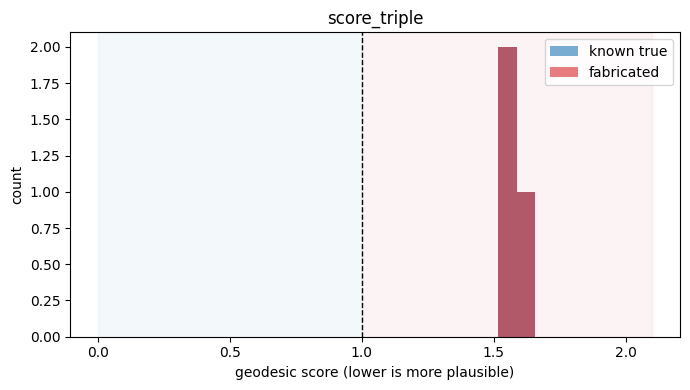

In [9]:
# Visualization 1: histogram of score_triple
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
ug.plot_triple_score_hist(scores_true, scores_false,
                          ax=ax, title='score_triple')
fig.tight_layout()
plt.show()


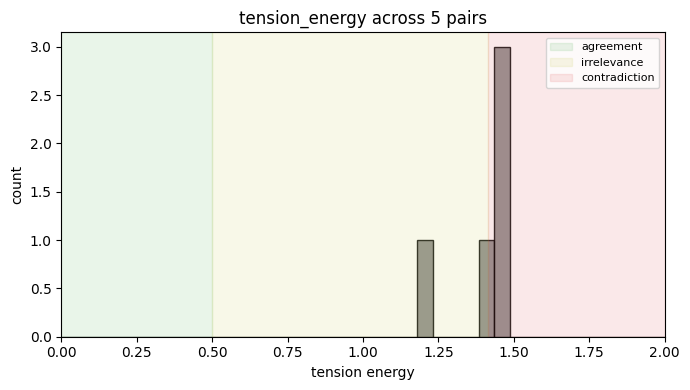

In [10]:
# Visualization 2: tension energy spectrum
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
ug.plot_tension_spectrum(tensions_clean, ax=ax,
                         title='tension_energy across 5 pairs')
fig.tight_layout()
plt.show()


### Exercises

1. Build a list of ten more (head, relation, tail) triples by sampling from `store.doc_graph.triples` and ten fabricated ones by swapping the tail; rerun the histogram.  Does the gap between known-true and fabricated widen?
2. Compute `tension_energy` for ten pairs of *model entities* (e.g. `LogisticRegression`, `Ridge`) and ten pairs of *condition entities* (e.g. `Need interpretability`).  Does either group concentrate in the agreement band?
3. Pick a (head, relation) that has multiple known tails in the document graph.  Does `link_predict` rank all of them in the top-5?

### What you should now be able to do

- Call each of the six GMS primitives.
- Read a `score_triple` histogram and explain the gap   between known and fabricated triples.
- Read a tension-energy spectrum across the three   bands.
- Distinguish a structural query (`query_triples`)   from a geometric ranking (`link_predict`).

### Cross-references

- USER_GUIDE.md section 4 (GMS Primitives Reference)
- `gms_agent_builder_ext/chapters/ch02.tex` and   `gmsh_testing_ext/chapters/ch02.tex` for the   primitives in book form
- `docgms/store.py:GMSExpertStore.score_triple` and   the five sibling methods.

In [11]:
# Final assertion: known triples are systematically more
# plausible than fabricated ones. The geodesic gap is
# narrow on a regex-mode fixture (no LLM augmentation);
# a hybrid-mode store widens it considerably and would
# admit a tighter `mean_true < 1.0` claim.
scores_true_clean = [s for s in scores_true if s is not None]
scores_false_clean = [s for s in scores_false if s is not None]
assert scores_true_clean, 'no scorable known triples'
assert scores_false_clean, 'no scorable fabricated triples'
mean_true = sum(scores_true_clean) / len(scores_true_clean)
mean_false = sum(scores_false_clean) / len(scores_false_clean)
assert mean_true < mean_false, (
    f'expected mean(known) < mean(fabricated); '
    f'got {mean_true:.4f} vs {mean_false:.4f}'
)
assert mean_true < 1.7, (
    f'true triples should score below 1.7 (regex bound); '
    f'got {mean_true:.4f}'
)
print(f'OK: mean(known)={mean_true:.4f} < '
      f'mean(fabricated)={mean_false:.4f}')


OK: mean(known)=1.5545 < mean(fabricated)=1.5743
